In [1]:
!pip install ucimlrepo -q

In [2]:
from ucimlrepo import fetch_ucirepo

# Download Student Performance dataset
student_data = fetch_ucirepo(id=320)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
import pandas as pd

# Get features and final grade
X_original = student_data.data.features
y_original = student_data.data.targets

# Combine them into one DataFrame
df = pd.concat([X_original, y_original], axis=1)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (649, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [6]:
df["Pass"] = (df["G3"] >= 10).astype(int)

df[["G3", "Pass"]].head(10)

,G3,Pass
0,11,1
1,11,1
2,12,1
3,14,1
4,13,1
5,13,1
6,13,1
7,13,1
8,17,1
9,13,1


In [7]:
df["Fail"] = (df["G3"] < 10).astype(int)

df[["G3", "Fail"]].head(10)

,G3,Fail
0,11,0
1,11,0
2,12,0
3,14,0
4,13,0
5,13,0
6,13,0
7,13,0
8,17,0
9,13,0


In [8]:
print(df["Pass"].value_counts())

Pass
1    549
0    100
Name: count, dtype: int64


In [9]:
print("Fail students:", (df["Pass"] == 0).sum())
print("Pass students:", (df["Pass"] == 1).sum())

Fail students: 100
Pass students: 549


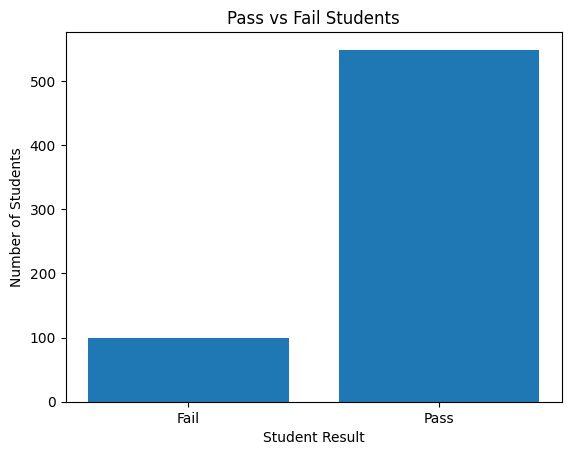

In [10]:
import matplotlib.pyplot as plt

counts = df["Pass"].value_counts().sort_index()

plt.bar(["Fail", "Pass"], counts)

plt.xlabel("Student Result")
plt.ylabel("Number of Students")
plt.title("Pass vs Fail Students")

plt.show()

In [11]:
features = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2"
]

X = df[features]
y = df["Pass"]

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   studytime  failures  absences  G1  G2
0          2         0         4   0  11
1          2         0         2   9  11
2          2         0         6  12  13
3          3         0         0  14  14
4          2         0         0  11  13

Target:
0    1
1    1
2    1
3    1
4    1
Name: Pass, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 519
Testing students: 130


In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [14]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[1 1 1 1 1 0 1 1 1 1]


In [15]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.9
Accuracy Percentage: 90.0 %


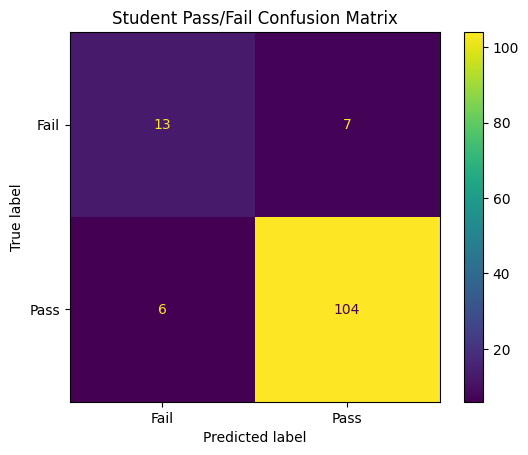

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Fail", "Pass"]
)

plt.title("Student Pass/Fail Confusion Matrix")
plt.show()

In [18]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.68      0.65      0.67        20
        Pass       0.94      0.95      0.94       110

    accuracy                           0.90       130
   macro avg       0.81      0.80      0.80       130
weighted avg       0.90      0.90      0.90       130



In [19]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(20)

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,0,0
6,0,1
7,1,1
8,1,1
9,1,1


In [20]:
df.to_csv(
    "student_pass_fail_dataset.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!
